# ML04: First model, logistic regression (Task 6)
**Goal:** a simple, honest baseline. Logistic regression turns a weighted sum of the precursors into a probability.

**Honest testing (the most important idea in this lesson):** we never test on years the model trained on.
Years 1979-2024 are split into 5 blocks of about 9 consecutive years; the model trains on 4 blocks and predicts the 5th, five times.
Consecutive blocks matter: neighbouring days are similar, so a random split would leak information and inflate the scores.
2025 is kept completely aside.

**Models compared**
1. Persistence: yesterday's rain only (a forecaster's simplest rule)
2. Logistic regression, lead 1 day only
3. Logistic regression, leads 1-3 days

In [1]:
import os, glob, warnings
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore', category=FutureWarning)

BASE = os.environ.get('PML_BASE', '/content/drive/MyDrive/PrecursorML')   # this project
EPE  = os.environ.get('PML_EPE',  '/content/drive/MyDrive/EPE2025')       # flood paper: shapefiles + shared IMD files
DATA, RES = f'{BASE}/data', f'{BASE}/results'
for d in (DATA, RES): os.makedirs(d, exist_ok=True)

TARGET      = 'ChenabRavi'                   # basin whose extreme rain days we predict
PCT         = 95                             # extreme day = IMD basin rain >= 95th percentile of JJAS days
YEARS       = list(range(1979, 2026))
TRAIN_YEARS = list(range(1979, 2025))        # 2025 is kept aside as an independent test
EPISODES    = {'E1': ('2025-08-23', '2025-08-26'), 'E2': ('2025-08-29', '2025-09-03')}   # START-date labels

In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

table = pd.read_csv(f'{DATA}/features_{TARGET}.csv', index_col=0, parse_dates=True)
y, yr = table['extreme'], table.index.year
ATMOS = [c_ for c_ in table if '_lag' in c_ and c_ != 'rain_lag1'] + ['doy_sin', 'doy_cos']
LAG1  = [c_ for c_ in ATMOS if c_.endswith('_lag1')] + ['doy_sin', 'doy_cos']
train = yr <= 2024
BLOCKS = np.array_split(TRAIN_YEARS, 5)        # 5 blocks of ~9 consecutive years: train on 4, test on 1
print(len(ATMOS), 'atmospheric features |', int(y[train].sum()), 'extreme days in', int(train.sum()), 'training days')

def cv_predict(make_model, cols):
    """Out-of-fold probabilities for 1979-2024: each block is predicted by a model that never saw those years."""
    p = pd.Series(np.nan, index=table.index[train])
    for blk in BLOCKS:
        te = np.isin(yr[train], blk); tr_ = ~te
        if te.sum() == 0: continue                 # block with no data yet (years still downloading)
        m = make_model().fit(table.loc[train, cols][tr_], y[train][tr_])
        p[te] = m.predict_proba(table.loc[train, cols][te])[:, 1]
    return p

def scores(p, name):
    yt = y[train]; base = yt.mean()
    k = max(1, int(round(0.05 * len(p))))                    # the 5% of days with the highest probability
    top = p.sort_values(ascending=False).index[:k]
    return dict(model=name,
                ROC_AUC=round(roc_auc_score(yt, p), 3),
                PR_AUC=round(average_precision_score(yt, p), 3), base_rate=round(base, 3),
                BSS=round(1 - brier_score_loss(yt, p) / brier_score_loss(yt, np.full(len(p), base)), 3),
                hit_rate_top5pct=round(yt.loc[top].mean(), 3),
                extremes_caught_top5pct=round(yt.loc[top].sum() / yt.sum(), 3))

def logreg(): return make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=5000))

def plot_2025(models, fname, title):
    """Fit each model on 1979-2024 and plot its 2025 probabilities with the IMD rain."""
    t25 = table[(yr == 2025)].loc['2025-07-15':'2025-09-20']
    fig, ax = plt.subplots(figsize=(13, 4.5), constrained_layout=True)
    ax2 = ax.twinx()
    ax2.bar(t25.index, t25['rain'], color='grey', alpha=.35, width=.8, label='IMD rain (right axis)')
    ax2.set_ylabel('IMD basin rain (mm/day)')
    for name, (make, cols) in models.items():
        m = make().fit(table.loc[train, cols], y[train])
        ax.plot(t25.index, m.predict_proba(t25[cols])[:, 1], '-o', ms=3, lw=1.8, label=name)
    for k, (a, b) in EPISODES.items():
        ax.axvspan(pd.Timestamp(a) - pd.Timedelta('12h'), pd.Timestamp(b) + pd.Timedelta('12h'), color='orange', alpha=.15)
        ax.text(pd.Timestamp(a), 0.97, k, transform=ax.get_xaxis_transform(), fontweight='bold')
    ax.axhline(y[train].mean(), color='k', ls=':', lw=1, label='climatology')
    ax.set_ylim(0, 1); ax.set_ylabel('P(extreme day)'); ax.set_title(title)
    ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
    ax.legend(loc='upper left', fontsize=8)
    plt.savefig(f'{RES}/{fname}', dpi=150); plt.show()

41 atmospheric features | 281 extreme days in 5566 training days


## 1. Cross-validated skill

In [3]:
oof = {'Persistence (rain yesterday)': cv_predict(logreg, ['rain_lag1']),
       'LogReg lead 1 day':            cv_predict(logreg, LAG1),
       'LogReg leads 1-3 days':        cv_predict(logreg, ATMOS)}
res = pd.DataFrame([scores(p, k) for k, p in oof.items()]).set_index('model')
res.to_csv(f'{RES}/ml04_scores.csv'); pd.DataFrame(oof).to_csv(f'{RES}/ml04_oof_probs.csv')
print(res.to_string())

                              ROC_AUC  PR_AUC  base_rate    BSS  hit_rate_top5pct  extremes_caught_top5pct
model                                                                                                     
Persistence (rain yesterday)    0.757   0.222       0.05  0.070             0.288                    0.285
LogReg lead 1 day               0.799   0.183       0.05  0.067             0.209                    0.206
LogReg leads 1-3 days           0.810   0.196       0.05  0.070             0.223                    0.221


**How to read the scores**
- **ROC AUC**: 0.5 = no skill (coin toss), 1 = perfect ranking of extreme vs normal days.
- **PR AUC**: compare with the base rate (about 0.05). Twice the base rate already means useful skill for rare events.
- **BSS** (Brier skill score): above 0 = better probabilities than always forecasting the climatological 5%.
- **hit_rate_top5pct**: of the 5% of days with the highest forecast probability, how many really were extreme.
- **extremes_caught_top5pct**: which share of all extreme days fall in that top 5%.

## 2. Reliability: when the model says 30%, does it rain extremely about 30% of the time?

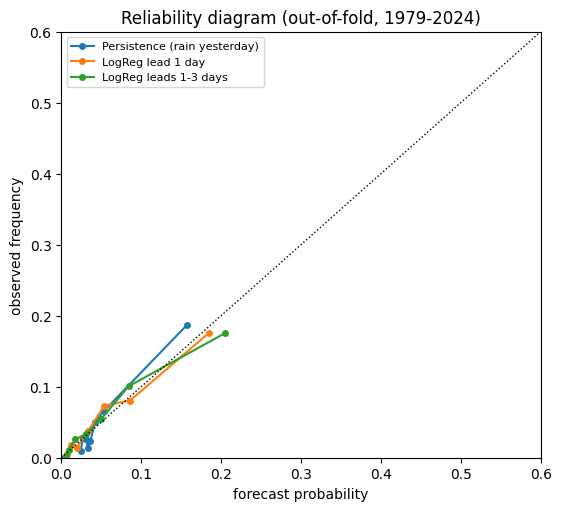

In [4]:
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(figsize=(5.5, 5), constrained_layout=True)
for k, p in oof.items():
    fy, fx = calibration_curve(y[train], p, n_bins=8, strategy='quantile')
    ax.plot(fx, fy, '-o', ms=4, label=k)
ax.plot([0, 1], [0, 1], 'k:', lw=1); ax.set_xlim(0, .6); ax.set_ylim(0, .6)
ax.set_xlabel('forecast probability'); ax.set_ylabel('observed frequency'); ax.legend(fontsize=8)
ax.set_title('Reliability diagram (out-of-fold, 1979-2024)')
plt.savefig(f'{RES}/ml04_reliability.png', dpi=150); plt.show()

## 3. What did the model learn? (standardized coefficients, model fitted on 1979-2024)

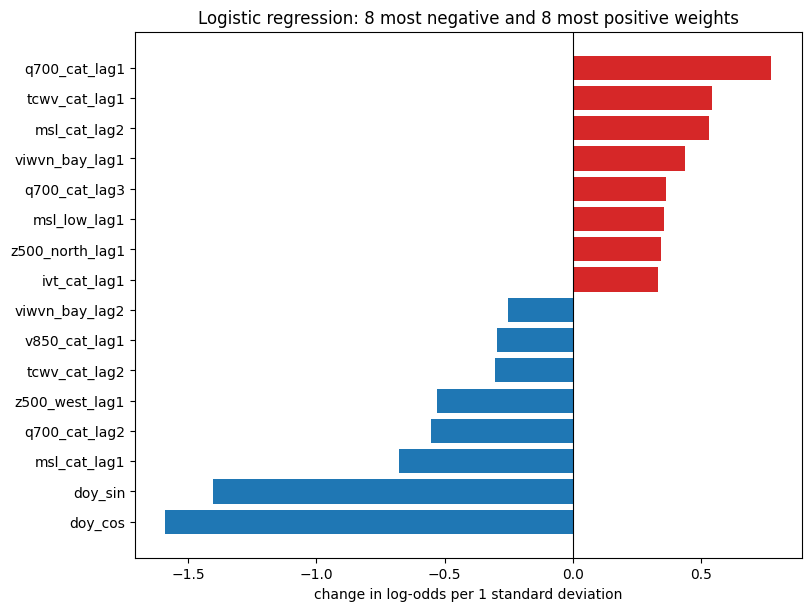

In [5]:
m = logreg().fit(table.loc[train, ATMOS], y[train])
coef = pd.Series(m[-1].coef_[0], index=ATMOS).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
ax.barh(top.index, top.values, color=['tab:blue' if v < 0 else 'tab:red' for v in top])
ax.axvline(0, color='k', lw=.8); ax.set_title('Logistic regression: 8 most negative and 8 most positive weights')
ax.set_xlabel('change in log-odds per 1 standard deviation'); plt.savefig(f'{RES}/ml04_coefficients.png', dpi=150); plt.show()

## 4. The real test: 2025 (never seen in training)

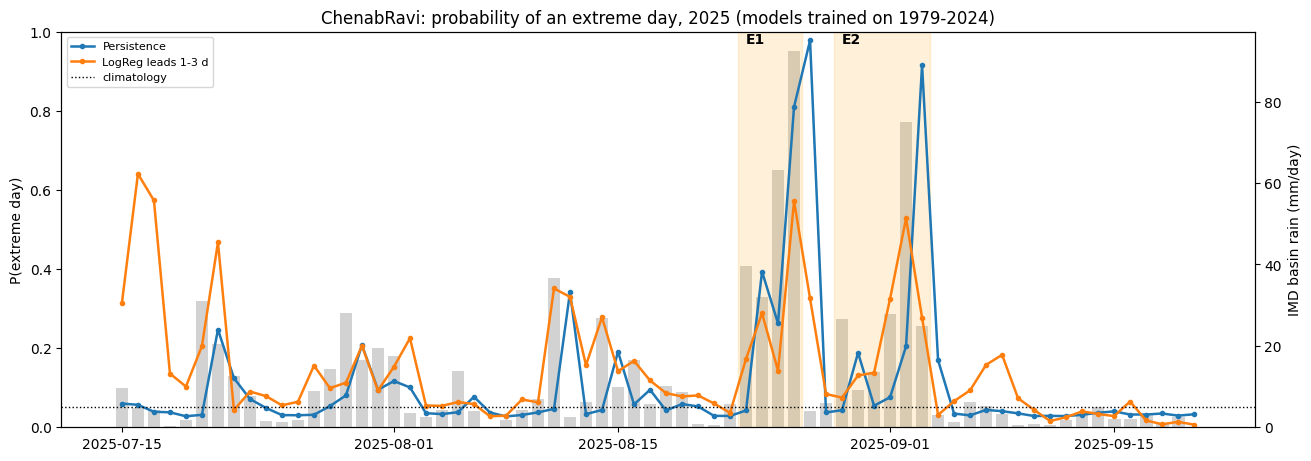

In [6]:
plot_2025({'Persistence': (logreg, ['rain_lag1']), 'LogReg leads 1-3 d': (logreg, ATMOS)},
          'ml04_forecast_2025.png', f'{TARGET}: probability of an extreme day, 2025 (models trained on 1979-2024)')

## Think about it
1. Does the atmospheric model beat persistence? By how much in ROC AUC and PR AUC?
2. Do leads 2-3 days add skill over lead 1 day alone?
3. On the 2025 plot, did the probability rise **before** E1 and E2? Were there false alarms?